# Empirical Investigation of the Central Limit Theorem (CLT)
## Stage 1: Problem Formulation & Data Exploration Setup

---

### 1. Project Objective

The **Central Limit Theorem (CLT)** is a cornerstone of probability theory and inferential statistics. In its classical form (the Lindeberg–Lévy CLT), it establishes that if $X_1, X_2, \dots, X_n$ is a sequence of independent and identically distributed (i.i.d.) random variables drawn from a population with a well-defined finite mean $\mu$ and finite variance $\sigma^2$, the standardized sample mean converges in distribution to a standard normal distribution as the sample size $n$ increases:

$$\sqrt{n} \left( \frac{\bar{X}_n - \mu}{\sigma} \right) \xrightarrow{d} \mathcal{N}(0, 1) \quad \text{as } n \to \infty$$

While introductory textbooks routinely demonstrate this convergence using synthetic, idealized distributions (such as uniform, exponential, or Poisson), real-world data introduces substantial practical complexities:
- **Severe skewness and heavy tails** (e.g., individual income distributions).
- **Bounded supports and discrete counts** (e.g., bike rental counts).
- **Physical boundaries and multimodal seasonal regimes** (e.g., meteorological measurements).
- **Potential violations of the i.i.d. assumption** arising from temporal autocorrelation and seasonality.

The objective of this project is to **empirically investigate the behavior, convergence dynamics, and practical boundaries of the Central Limit Theorem** using diverse real-world datasets.

#### Why Understand Original Population Distributions First?
Before analyzing how sample means converge toward normality, we must establish an empirical baseline of the underlying parent populations:
1. **Convergence Rate Sensitivity:** The Berry–Esseen theorem establishes that the maximum approximation error between the cumulative distribution function of the standardized sample mean $F_n(x)$ and the standard normal $\Phi(x)$ is bounded by:
   $$|F_n(x) - \Phi(x)| \le \frac{C \cdot \rho}{\sigma^3 \sqrt{n}}$$
   where $\rho = \mathbb{E}[|X - \mu|^3]$ is the third absolute central moment and $C$ is a universal constant. The rate of convergence is therefore directly governed by the skewness and kurtosis of the parent population. Symmetrical, light-tailed populations achieve near-normality at modest sample sizes ($n \approx 30$), whereas heavily skewed or fat-tailed populations require substantially larger cohorts ($n \gg 100$) before normality approximations become reliable.
2. **Identification of Structural Nuances:** Baseline exploration uncovers critical real-world phenomena—such as zero-inflation, top-coding, physical clamping, and serial correlation—that dictate appropriate sampling protocols and inform the interpretation of simulation outcomes.

---

### 2. Environment and Imports

We configure the analytical environment with the core scientific Python stack:
- **`pathlib.Path`** for robust cross-platform path resolution.
- **`pandas`** and **`numpy`** for data ingestion, array operations, and descriptive statistics.
- **`matplotlib.pyplot`** and **`seaborn`** for distribution visualizations.
- **`scipy.stats`** for statistical testing and theoretical distribution fitting.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Configure plotting aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 100,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
})

print(f"Python interpreter: {sys.version.split()[0]}")
print(f"NumPy version:      {np.__version__}")
print(f"Pandas version:     {pd.__version__}")
print(f"Matplotlib version: {plt.matplotlib.__version__}")
print(f"Seaborn version:    {sns.__version__}")
print(f"SciPy version:      {stats.__version__ if hasattr(stats, '__version__') else 'available'}")
print("\nEnvironment and libraries configured successfully.")

Python interpreter: 3.13.14
NumPy version:      2.3.1
Pandas version:     3.0.0
Matplotlib version: 3.10.8
Seaborn version:    0.13.2
SciPy version:      available

Environment and libraries configured successfully.


---

### 3. Dataset Inventory

The project structure organizes raw data under `data/raw/`. The cell below automatically inspects this directory, identifies any existing CSV files, reports their relative paths and file sizes, and handles scenarios where datasets have not yet been placed into the directory without raising errors.

In [2]:
# Resolve project root and raw data directory
notebook_dir = Path.cwd()
project_root = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir
raw_data_dir = project_root / "data" / "raw"

print(f"Resolved project root: {project_root.resolve()}")
print(f"Target raw directory:  {raw_data_dir.resolve()}\n")

if not raw_data_dir.exists():
    print(f"Status: Directory '{raw_data_dir}' does not exist yet.")
    csv_files = []
else:
    # Identify all CSV files recursively inside data/raw/
    csv_files = sorted(raw_data_dir.rglob("*.csv"))

if csv_files:
    inventory = []
    for f in csv_files:
        size_bytes = f.stat().st_size
        if size_bytes >= 1024 * 1024:
            size_formatted = f"{size_bytes / (1024 * 1024):.2f} MB"
        elif size_bytes >= 1024:
            size_formatted = f"{size_bytes / 1024:.2f} KB"
        else:
            size_formatted = f"{size_bytes} B"
            
        inventory.append({
            "Filename": f.name,
            "Relative Path": str(f.relative_to(raw_data_dir)),
            "Size": size_formatted,
            "Size (bytes)": size_bytes
        })
    inventory_df = pd.DataFrame(inventory)
    print(f"Discovered {len(csv_files)} CSV file(s) in 'data/raw/':")
    display(inventory_df)
else:
    print("[Inventory Status] No CSV files found in 'data/raw/' yet.")
    print("Datasets can be placed into 'data/raw/' before running downstream ingestion.")

Resolved project root: G:\Analysis1
Target raw directory:  G:\Analysis1\data\raw



Discovered 4 CSV file(s) in 'data/raw/':


,Filename,Relative Path,Size,Size (bytes)
0,day.csv,day.csv,56.22 KB,57569
1,hour.csv,hour.csv,1.10 MB,1156736
2,open-meteo-22.60N88.40E12m.csv,open-meteo-22.60N88.40E12m.csv,148.56 KB,152127
3,psam_p06.csv,psam_p06.csv,265.34 MB,278224148


---

### 4. Investigation Framework

To evaluate the Central Limit Theorem across differing real-world scenarios, we examine three planned datasets:

#### 1. Individual Income Distribution (Census ACS PUMS California)
- **Target Domain:** Socioeconomic microdata (U.S. Census Bureau American Community Survey Public Use Microdata Sample, California person-level records).
- **Distributional Characteristics:** Severely right-skewed, heavy Pareto-like tail, concentrated mass near median with extreme high-income outliers, and non-positive values (e.g., business losses).
- **Analytical Intent:** 
  - Measure empirical skewness and kurtosis.
  - Test the sample size threshold ($n$) necessary for the sampling distribution of the mean to overcome extreme skewness and achieve normality.
  - Assess how heavy tails affect the standard error formula $\frac{\sigma}{\sqrt{n}}$ and empirical confidence interval coverage.

#### 2. Bike Sharing Demand (`day.csv` and `hour.csv`)
- **Target Domain:** Municipal transportation demand (Capital Bikeshare system records).
- **Distributional Characteristics:** Non-negative count data, right-skewed hourly counts, diurnal commuter peaks (multimodality), seasonality, and strong temporal autocorrelation.
- **Analytical Intent:**
  - Compare distribution geometry across temporal aggregations (hourly vs. daily aggregation).
  - Investigate the effect of serial dependence (violations of the i.i.d. assumption) on the variance of the sample mean.
  - Assess convergence behavior when drawing samples from a multimodal parent distribution.

#### 3. Kolkata Historical Weather (`kolkata_weather.csv`)
- **Target Domain:** Atmospheric and environmental continuous physical measurements.
- **Distributional Characteristics:** Continuous thermodynamic variables (mean, minimum, and maximum daily temperatures) bounded by regional atmospheric limits, with distinct seasonal clusters (monsoon, winter, summer).
- **Analytical Intent:**
  - Study sampling behavior from continuous, bounded, potentially bimodal or multi-modal seasonal mixtures.
  - Compare random sampling across the full multi-year record against stratified sampling within individual seasons.
  - Analyze the stability of the sample mean relative to seasonal cyclicality.

---

### 5. Initial Research Questions

Our empirical study is structured around five core research questions:

1. **What are the shapes of the original distributions?**
   - How do the empirical histograms and kernel density estimates (KDE) compare across the three datasets?
   - What are the quantitative measures of asymmetry (Fisher-Pearson skewness $g_1$) and peakedness/tail weight (excess kurtosis $g_2$)?

2. **Are they symmetric, skewed, or multimodal?**
   - Does individual income exhibit a monotonic long-tail decay?
   - Does hourly bike rental exhibit distinct commuter-driven bimodal peaks?
   - Does Kolkata daily temperature exhibit seasonal mixture modes or bounded bell shapes?

3. **How do their means and standard deviations compare?**
   - How do parametric measures of location and spread (mean $\mu$, standard deviation $\sigma$) compare with robust, non-parametric statistics (median, interquartile range IQR)?
   - How sensitive is the empirical mean to extreme outliers in each domain?

4. **What unusual observations or patterns exist?**
   - Are there structural zeros, negative values, or top-coded threshold caps in the income data?
   - Are there zero-count periods or weather-induced demand shocks in the bike-sharing records?
   - Are there seasonal plateaus or extreme temperature anomalies in the meteorological data?

5. **What sampling challenges might each dataset present?**
   - **Independence Violations:** Serial autocorrelation in the bike-sharing and weather time series violates the strict i.i.d. assumption. How does temporal dependence inflate the effective standard error?
   - **Severe Skewness:** By the Berry–Esseen theorem, extreme skewness in income data slows convergence. Will the classical rule of thumb ($n = 30$) be insufficient?
   - **Finite Variance Requirement:** Are all empirical distributions bounded and well-behaved with finite second moments?

---

### Roadmap for Upcoming Stages
- **Stage 2:** Data Ingestion & Schema Auditing (reading CSV files once added, checking data types, cleaning missing values).
- **Stage 3:** Exploratory Data Analysis & Population Parameter Estimation (computing $\mu$, $\sigma$, skewness, kurtosis).
- **Stage 4:** Monte Carlo Sampling Experiments (simulating sample means across $n \in \{5, 15, 30, 50, 100, 500, 1000\}$).
- **Stage 5:** Normality Testing, Q-Q Diagnostics, and Central Limit Theorem Boundary Analysis.

Observations: 731
Mean: 4504.35
Standard deviation: 1937.21


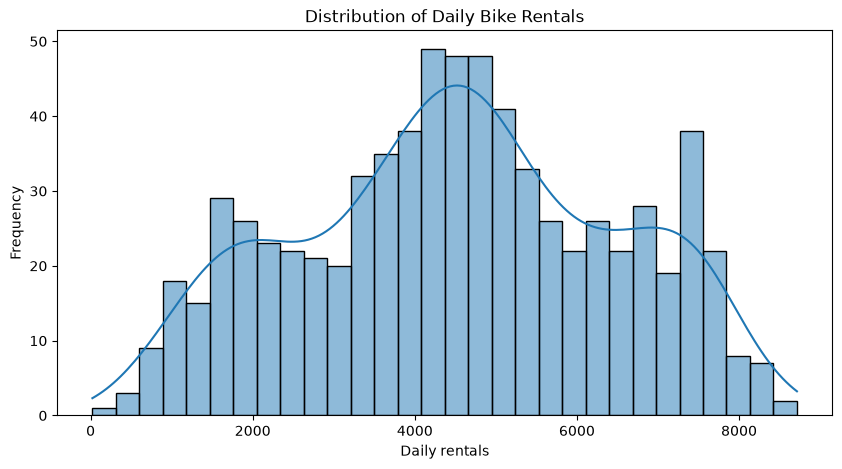

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate and load the dataset
candidates = [
    Path("data/raw/day.csv"),
    Path("../data/raw/day.csv")
]

data_path = next((p for p in candidates if p.exists()), None)

if data_path is None:
    raise FileNotFoundError("Could not find day.csv in data/raw/")

bike = pd.read_csv(data_path)

# Extract daily rental counts
rentals = bike["cnt"].dropna()

print(f"Observations: {len(rentals)}")
print(f"Mean: {rentals.mean():.2f}")
print(f"Standard deviation: {rentals.std():.2f}")

# Plot the original distribution
plt.figure(figsize=(10, 5))
sns.histplot(rentals, bins=30, kde=True)

plt.title("Distribution of Daily Bike Rentals")
plt.xlabel("Daily rentals")
plt.ylabel("Frequency")
plt.show()

Number of sample means: 10000
Mean of sample means: 4506.29
SD of sample means: 354.88


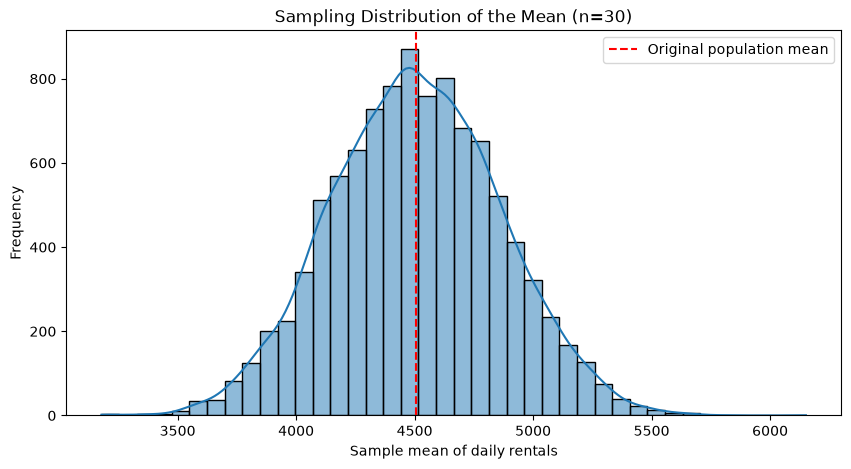

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)

sample_size = 30
n_simulations = 10_000

# Draw 10,000 independent samples, each containing 5 observations
samples = rng.choice(
    rentals,
    size=(n_simulations, sample_size),
    replace=True
)

# Calculate the mean of each sample
sample_means = samples.mean(axis=1)

# Examine the sampling distribution
print(f"Number of sample means: {len(sample_means)}")
print(f"Mean of sample means: {sample_means.mean():.2f}")
print(f"SD of sample means: {sample_means.std():.2f}")

plt.figure(figsize=(10, 5))
sns.histplot(sample_means, bins=40, kde=True)

plt.axvline(
    rentals.mean(),
    color="red",
    linestyle="--",
    label="Original population mean"
)

plt.title(f"Sampling Distribution of the Mean (n={sample_size})")
plt.xlabel("Sample mean of daily rentals")
plt.ylabel("Frequency")
plt.legend()
plt.show()